# First-Order Wave Equation

$$\frac{\partial \psi}{\partial t} + v\,\frac{\partial \psi}{\partial x} = 0$$

Discretised with the **upwind (first-order) scheme** for $v > 0$:

$$\psi_i^{n+1} = \psi_i^{n} - k\left(\psi_i^{n} - \psi_{i-1}^{n}\right), \qquad k = \frac{v\,\Delta t}{\Delta x}$$

The CFL condition for stability is $0 \le k \le 1$. Periodic boundary conditions are used, so a pulse leaving one end re-enters from the other.

In [37]:
import numpy as np 
import matplotlib.pyplot as plt

# Parameters
N = 200
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
v = 1.0                 # wave speed
k = 0.5                 # CFL number, v*dt/dx (must satisfy 0 <= k <= 1)
dt = k * dx / v
t_end = 0.5
nt = int(round(t_end / dt))

In [38]:
# Initial Conditions
psi = np.exp(-200 * (x - 0.25)**2)
psi_0 = psi.copy()
psi_T = []

# Exact solution: the initial profile simply translates by v*t
def exact(x, t):
    return np.exp(-200 * (((x - v*t) % L) - 0.25)**2)

In [39]:
# Time integration with the upwind scheme (periodic boundary conditions)
for n in range(nt):
    psi_new = np.zeros(N)
    for i in range(1, N):
        psi_new[i] = psi[i] - k*(psi[i] - psi[i-1])
    # Periodic wrap-around at the left boundary
    psi_new[0] = psi[0] - k*(psi[0] - psi[-1])
    psi = psi_new
    psi_T.append(psi.copy())

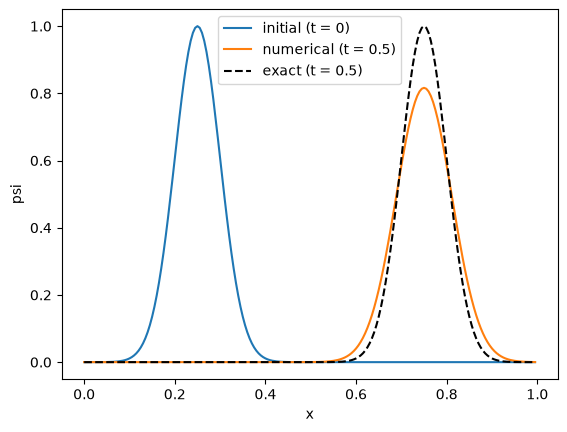

In [40]:
plt.plot(x, psi_0, label='initial (t = 0)')
plt.plot(x, psi, label=f'numerical (t = {t_end})')
plt.plot(x, exact(x, t_end), 'k--', label=f'exact (t = {t_end})')
plt.xlabel('x')
plt.ylabel('psi')
plt.legend()
plt.show()

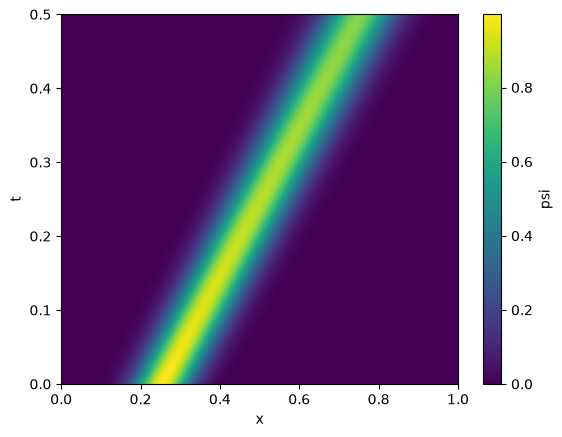

In [41]:
# Space-time evolution of the pulse
psi_T = np.array(psi_T)
plt.imshow(psi_T, aspect='auto', origin='lower',
           extent=[0, L, 0, t_end], cmap='viridis')
plt.colorbar(label='psi')
plt.xlabel('x')
plt.ylabel('t')
plt.show()